In [1]:
import time
import math
import numpy as np
import matplotlib.pyplot as plt


# Recursive matrix multiplication using Binét's method

In [22]:
def generate_random_matrix(size: int, low: float = 0.00000001, high: float = 1.0):
    """ returns matrix size x size with random values in range of (low, high) """

    return high - (high - low) * np.random.rand(size, size)


def next_pow2(n: int) -> int:
    if n <= 1:
        return 1
    return 1 << (n - 1).bit_length()


def next_pow3(n: int) -> int:
    p = 1
    while p < n:
        p *= 3
    return p

sizes = [2, 4, 10, 20, 50, 100]
A_multiple = [generate_random_matrix(size) for size in sizes]
B_multiple = [generate_random_matrix(size) for size in sizes]


In [23]:
def binet(A, B):
    m_ops = 0
    a_s_ops = 0

    def rec(A_i_s, A_i_e, A_j_s, A_j_e,
            B_i_s, B_i_e, B_j_s, B_j_e):
        nonlocal m_ops, a_s_ops

        if A_i_e - A_i_s == 1:
            m_ops += 1
            return np.array([[A_padded[A_i_s][A_j_s] * B_padded[B_i_s][B_j_s]]])

        mid_i_A = A_i_s + (A_i_e - A_i_s) // 2
        mid_j_A = A_j_s + (A_j_e - A_j_s) // 2

        se_11_A = ((A_i_s, mid_i_A), (A_j_s, mid_j_A))
        se_12_A = ((A_i_s, mid_i_A), (mid_j_A, A_j_e))
        se_21_A = ((mid_i_A, A_i_e), (A_j_s, mid_j_A))
        se_22_A = ((mid_i_A, A_i_e), (mid_j_A, A_j_e))

        mid_i_B = B_i_s + (B_i_e - B_i_s) // 2
        mid_j_B = B_j_s + (B_j_e - B_j_s) // 2

        se_11_B = ((B_i_s, mid_i_B), (B_j_s, mid_j_B))
        se_12_B = ((B_i_s, mid_i_B), (mid_j_B, B_j_e))
        se_21_B = ((mid_i_B, B_i_e), (B_j_s, mid_j_B))
        se_22_B = ((mid_i_B, B_i_e), (mid_j_B, B_j_e))

        C_11 = (rec(*se_11_A[0], *se_11_A[1], *se_11_B[0], *se_11_B[1]) +
                rec(*se_12_A[0], *se_12_A[1], *se_21_B[0], *se_21_B[1]))
        a_s_ops += C_11.size

        C_12 = (rec(*se_11_A[0], *se_11_A[1], *se_12_B[0], *se_12_B[1]) +
                rec(*se_12_A[0], *se_12_A[1], *se_22_B[0], *se_22_B[1]))
        a_s_ops += C_12.size

        C_21 = (rec(*se_21_A[0], *se_21_A[1], *se_11_B[0], *se_11_B[1]) +
                rec(*se_22_A[0], *se_22_A[1], *se_21_B[0], *se_21_B[1]))
        a_s_ops += C_21.size

        C_22 = (rec(*se_21_A[0], *se_21_A[1], *se_12_B[0], *se_12_B[1]) +
                rec(*se_22_A[0], *se_22_A[1], *se_22_B[0], *se_22_B[1]))
        a_s_ops += C_22.size

        return np.block([[C_11, C_12], [C_21, C_22]])

    m_A, n_A = A.shape
    m_B, n_B = B.shape

    if n_A != m_B:
        raise Exception

    n = next_pow2(max(m_A, n_A, m_B, n_B))
    A_padded = np.pad(A, ((0, n - m_A), (0, n - n_A)), mode='constant')
    B_padded = np.pad(B, ((0, n - m_B), (0, n - n_B)), mode='constant')
    result = rec(0, n, 0, n, 0, n, 0, n)[:m_A, :n_B]
    return result, m_ops, a_s_ops


In [ ]:
print("idx equal close size m_ops a_s_ops")
for idx in range(len(sizes)):
    A = A_multiple[idx]
    B = B_multiple[idx]

    np_multiplication = A @ B
    strassen_multiplication, m_ops, a_s_ops = binet(A, B)

    print(
        f"{idx} {np.array_equal(np_multiplication, strassen_multiplication)} "
        f"{np.allclose(np_multiplication, strassen_multiplication)} {sizes[idx]} {m_ops} {a_s_ops}"
    )


idx equal close size m_ops a_s_ops
0 True True 2 8 4
1 False True 4 64 48
2 False True 10 4096 3840
3 False True 20 32768 31744
4 False True 50 262144 258048
5 False True 100 2097152 2080768


# Recursive matrix multiplication using Strassen's method

In [17]:
def strassen(A, B):
    m_ops = 0
    a_s_ops = 0

    def add(X, Y):
        nonlocal m_ops, a_s_ops
        a_s_ops += X.size
        return X + Y

    def sub(X, Y):
        nonlocal a_s_ops
        a_s_ops += X.size
        return X - Y

    def rec(X, Y):
        nonlocal m_ops
        n = X.shape[0]

        if n == 1:
            m_ops += 1
            return np.array([[X[0, 0] * Y[0, 0]]])

        mid = n // 2

        A11 = X[:mid, :mid]
        A12 = X[:mid, mid:]
        A21 = X[mid:, :mid]
        A22 = X[mid:, mid:]

        B11 = Y[:mid, :mid]
        B12 = Y[:mid, mid:]
        B21 = Y[mid:, :mid]
        B22 = Y[mid:, mid:]

        M1 = rec(add(A11, A22), add(B11, B22))
        M2 = rec(add(A21, A22), B11)
        M3 = rec(A11, sub(B12, B22))
        M4 = rec(A22, sub(B21, B11))
        M5 = rec(add(A11, A12), B22)
        M6 = rec(sub(A21, A11), add(B11, B12))
        M7 = rec(sub(A12, A22), add(B21, B22))

        C11 = add(sub(add(M1, M4), M5), M7)
        C12 = add(M3, M5)
        C21 = add(M2, M4)
        C22 = add(sub(add(M1, M3), M2), M6)

        return np.block([[C11, C12], [C21, C22]])

    m_A, n_A = A.shape
    m_B, n_B = B.shape

    if n_A != m_B:
        raise Exception

    n = next_pow2(max(m_A, n_A, m_B, n_B))
    A_padded = np.pad(A, ((0, n - m_A), (0, n - n_A)), mode='constant')
    B_padded = np.pad(B, ((0, n - m_B), (0, n - n_B)), mode='constant')
    result = rec(A_padded, B_padded)[:m_A, :n_B]
    return result, m_ops, a_s_ops


In [25]:
print("idx equal close size m_ops a_s_ops")
for idx in range(len(sizes)):
    A = A_multiple[idx]
    B = B_multiple[idx]

    np_multiplication = A @ B
    strassen_multiplication, m_ops, a_s_ops = strassen(A, B)

    print(
        f"{idx} {np.array_equal(np_multiplication, strassen_multiplication)} "
        f"{np.allclose(np_multiplication, strassen_multiplication)} {sizes[idx]} {m_ops} {a_s_ops}"
    )


idx equal close size m_ops a_s_ops
0 False True 2 7 18
1 False True 4 49 198
2 False True 10 2401 12870
3 False True 20 16807 94698
4 False True 50 117649 681318
5 False True 100 823543 4842954


# Recursive matrix multiplication using Laderman's method

In [80]:
def laderman(A, B):
    ops = 0

    def add(X, Y):
        nonlocal ops
        ops += X.size
        return X + Y

    def sub(X, Y):
        nonlocal ops
        ops += X.size
        return X - Y

    def rec(X, Y):
        nonlocal ops
        n = X.shape[0]

        if n == 1:
            ops += 1
            return np.array([[X[0, 0] * Y[0, 0]]])

        m = n // 3

        A11 = X[0:m, 0:m]
        A12 = X[0:m, m:2*m]
        A13 = X[0:m, 2*m:3*m]
        A21 = X[m:2*m, 0:m]
        A22 = X[m:2*m, m:2*m]
        A23 = X[m:2*m, 2*m:3*m]
        A31 = X[2*m:3*m, 0:m]
        A32 = X[2*m:3*m, m:2*m]
        A33 = X[2*m:3*m, 2*m:3*m]

        B11 = Y[0:m, 0:m]
        B12 = Y[0:m, m:2*m]
        B13 = Y[0:m, 2*m:3*m]
        B21 = Y[m:2*m, 0:m]
        B22 = Y[m:2*m, m:2*m]
        B23 = Y[m:2*m, 2*m:3*m]
        B31 = Y[2*m:3*m, 0:m]
        B32 = Y[2*m:3*m, m:2*m]
        B33 = Y[2*m:3*m, 2*m:3*m]

        M1 = rec(sub(sub(sub(add(add(A11, A12), A13), A21), A22), add(A32, A33)), B22)
        M2 = rec(sub(A11, A21), sub(B22, B12))
        M3 = rec(A22, add(sub(sub(sub(add(sub(B12, B11), B21), B22), B23), B31), B33))
        M4 = rec(add(sub(A21, A11), A22), add(sub(B11, B12), B22))
        M5 = rec(add(A21, A22), sub(B12, B11))
        M6 = rec(A11, B11)
        M7 = rec(add(sub(A31, A11), A32), add(sub(B11, B13), B23))
        M8 = rec(sub(A31, A11), sub(B13, B23))
        M9 = rec(add(A31, A32), sub(B13, B11))
        M10 = rec(sub(sub(sub(add(add(A11, A12), A13), A22), A23), add(A31, A32)), B23)
        M11 = rec(A32, add(sub(sub(sub(add(sub(B13, B11), B21), B22), B23), B31), B32))
        M12 = rec(add(sub(A32, A13), A33), sub(add(B22, B31), B32))
        M13 = rec(sub(A13, A33), sub(B22, B32))
        M14 = rec(A13, B31)
        M15 = rec(add(A32, A33), sub(B32, B31))
        M16 = rec(add(sub(A22, A13), A23), sub(add(B23, B31), B33))
        M17 = rec(sub(A13, A23), sub(B23, B33))
        M18 = rec(add(A22, A23), sub(B33, B31))
        M19 = rec(A12, B21)
        M20 = rec(A23, B32)
        M21 = rec(A21, B13)
        M22 = rec(A31, B12)
        M23 = rec(A33, B33)

        C11 = add(add(M6, M14), M19)
        C12 = add(add(add(add(add(add(M1, M4), M5), M6), M12), M14), M15)
        C13 = add(add(add(add(add(add(M6, M7), M9), M10), M14), M16), M18)
        C21 = add(add(add(add(add(add(M2, M3), M4), M6), M14), M16), M17)
        C22 = add(add(add(add(M2, M4), M5), M6), M20)
        C23 = add(add(add(add(M14, M16), M17), M18), M21)
        C31 = add(add(add(add(add(add(M6, M7), M8), M11), M12), M13), M14)
        C32 = add(add(add(add(M12, M13), M14), M15), M22)
        C33 = add(add(add(add(M6, M7), M8), M9), M23)

        return np.block([
            [C11, C12, C13],
            [C21, C22, C23],
            [C31, C32, C33],
        ])

    m_A, n_A = A.shape
    m_B, n_B = B.shape

    if n_A != m_B:
        raise Exception

    n = next_pow3(max(m_A, n_A, m_B, n_B))
    A_padded = np.pad(A, ((0, n - m_A), (0, n - n_A)), mode='constant')
    B_padded = np.pad(B, ((0, n - m_B), (0, n - n_B)), mode='constant')
    result = rec(A_padded, B_padded)[:m_A, :n_B]
    return result, ops


In [81]:
print("idx equal close ops")
for idx in range(matrix_cnt):
    A = A_multiple[idx]
    B = B_multiple[idx]

    np_multiplication = A @ B
    laderman_multiplication, ops = laderman(A, B)

    print(
        f"{idx} {np.array_equal(np_multiplication, laderman_multiplication)} "
        f"{np.allclose(np_multiplication, laderman_multiplication)} {ops}"
    )


idx equal close ops
0 True True 1
1 False True 121
2 False True 121
3 False True 3665
4 False True 3665
5 False True 3665
6 False True 3665
7 False True 3665
8 False True 3665
9 False True 92233
10 False True 92233
11 False True 92233
12 False True 92233
13 False True 92233
14 False True 92233
15 False True 92233


# Matrix multiplication using AlphaTensor (AI / Nature)

In [3]:
factorizations = dict(np.load("alphatensor/factorizations_r.npz", allow_pickle=True))
u4, v4, w4 = factorizations["4,4,4"]
print("4x4 factorization rank:", u4.shape[-1])

print(list(factorizations.keys()))
def alphatensor(A, B):
    """AlphaTensor 4x4 multiply from factorizations_r.npz. Returns (C, ops)."""
    if A.shape != (4, 4) or B.shape != (4, 4):
        raise ValueError("alphatensor supports only 4x4 matrices")

    ops = 0
    A_flat = A.reshape(-1)
    B_flat = B.reshape(-1)
    rank = u4.shape[-1]

    S = np.zeros(rank)
    T = np.zeros(rank)

    for r in range(rank):
        first = True
        for i in range(16):
            coef = u4[i, r]
            if coef == 0:
                continue
            if first:
                S[r] = A_flat[i] if coef == 1 else -A_flat[i]
                first = False
            else:
                S[r] = S[r] + A_flat[i] if coef == 1 else S[r] - A_flat[i]
                ops += 1

        first = True
        for j in range(16):
            coef = v4[j, r]
            if coef == 0:
                continue
            if first:
                T[r] = B_flat[j] if coef == 1 else -B_flat[j]
                first = False
            else:
                T[r] = T[r] + B_flat[j] if coef == 1 else T[r] - B_flat[j]
                ops += 1

    P = S * T
    ops += rank

    C_sym_flat = np.zeros(16)
    for k in range(16):
        first = True
        for r in range(rank):
            coef = w4[k, r]
            if coef == 0:
                continue
            term = P[r] if coef == 1 else -P[r]
            if first:
                C_sym_flat[k] = term
                first = False
            else:
                C_sym_flat[k] = C_sym_flat[k] + term
                ops += 1

    # factorization builds (A @ B).T
    C = C_sym_flat.reshape(4, 4).T
    return C, ops


4x4 factorization rank: 49
['2,2,2', '2,2,3', '2,2,4', '2,2,5', '2,2,6', '2,2,7', '2,2,8', '2,3,3', '2,3,4', '2,3,5', '2,4,4', '2,4,5', '2,5,5', '3,3,3', '3,3,4', '3,3,5', '3,4,4', '3,4,5', '3,4,11', '3,5,5', '3,5,9', '3,9,11', '4,4,4', '4,4,5', '4,5,5', '4,5,9', '4,5,10', '4,5,11', '4,9,10', '4,9,11', '4,11,11', '4,11,12', '5,5,5', '5,5,7', '5,7,9', '5,7,10', '5,7,11', '5,8,9', '5,8,10', '5,8,11', '5,9,9', '5,9,10', '5,9,11', '5,9,12', '6,7,9', '6,7,10', '6,7,11', '6,8,10', '6,8,11', '6,9,9', '6,9,10', '6,9,11', '7,7,9', '7,7,10', '7,7,11', '7,8,9', '7,8,10', '7,8,11', '7,8,12', '7,9,9', '7,9,10', '7,9,11', '7,9,12', '7,10,10', '7,10,11', '7,11,11', '8,8,10', '8,8,11', '8,9,10', '8,9,11', '8,9,12', '8,10,10', '8,10,11', '8,10,12', '8,11,11', '8,11,12', '9,9,9', '9,9,10', '9,9,11', '9,10,10', '9,10,11', '9,10,12', '9,11,11', '9,11,12', '10,10,10', '10,10,11', '10,10,12', '10,11,11', '10,11,12', '10,12,12', '11,11,11', '11,11,12', '11,12,12']


In [83]:
print("idx equal close ops")
for idx in range(10):
    A = generate_random_matrix(4)
    B = generate_random_matrix(4)

    np_multiplication = A @ B
    ai_multiplication, ops = alphatensor(A, B)

    print(
        f"{idx} {np.array_equal(np_multiplication, ai_multiplication)} "
        f"{np.allclose(np_multiplication, ai_multiplication)} {ops}"
    )


idx equal close ops
0 False True 517
1 False True 517
2 False True 517
3 False True 517
4 False True 517
5 False True 517
6 False True 517
7 False True 517
8 False True 517
9 False True 517


# Performance charts

In [30]:
plot_sizes = [2, 3, 4, 5, 6, 8, 9, 12, 16, 18, 24, 27, 32, 50, 100]

binet_times, strassen_times, laderman_times = [], [], []
binet_m_ops, strassen_m_ops = [], []
binet_a_s_ops, strassen_a_s_ops = [], []
ai_time = None
ai_ops = None

for n in plot_sizes:
    A = generate_random_matrix(n)
    B = generate_random_matrix(n)

    t0 = time.perf_counter()
    _, m_ops, a_s_ops = binet(A, B)
    binet_times.append(time.perf_counter() - t0)
    binet_m_ops.append(m_ops)
    binet_a_s_ops.append(m_ops)

    t0 = time.perf_counter()
    _, m_ops, a_s_ops = strassen(A, B)
    strassen_times.append(time.perf_counter() - t0)
    strassen_m_ops.append(m_ops)
    strassen_a_s_ops.append(a_s_ops)
    # t0 = time.perf_counter()
    # _, ops = laderman(A, B)
    # laderman_times.append(time.perf_counter() - t0)
    # laderman_ops.append(ops)

    # if n == 4:
    #     t0 = time.perf_counter()
    #     _, ai_ops = alphatensor(A, B)
    #     ai_time = time.perf_counter() - t0

print("done timing")


done timing


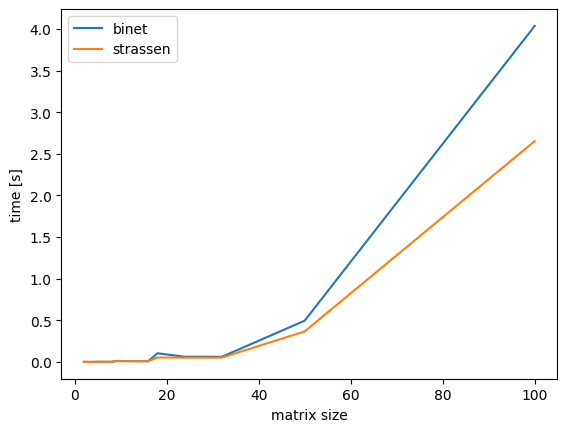

In [31]:
plt.plot(plot_sizes, binet_times, label="binet")
plt.plot(plot_sizes, strassen_times, label="strassen")
#plt.plot(plot_sizes, laderman_times, label="laderman")
#if ai_time is not None:
#    plt.plot([4], [ai_time], "o", label="alphatensor")
plt.xlabel("matrix size")
plt.ylabel("time [s]")
plt.legend()
plt.show()


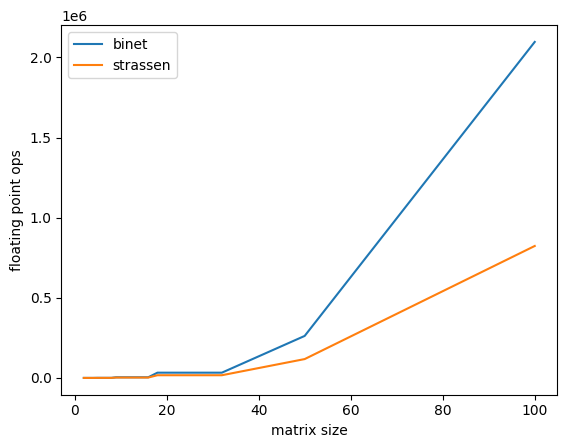

In [ ]:
plt.plot(plot_sizes, binet_m_ops, label="binet")
plt.plot(plot_sizes, strassen_m_ops, label="strassen")
# plt.plot(plot_sizes, laderman_ops, label="laderman")
# if ai_ops is not None:
#     plt.plot([4], [ai_ops], "o", label="alphatensor")
plt.xlabel("matrix size")
plt.ylabel("multiplication ops")
plt.legend()
plt.show()


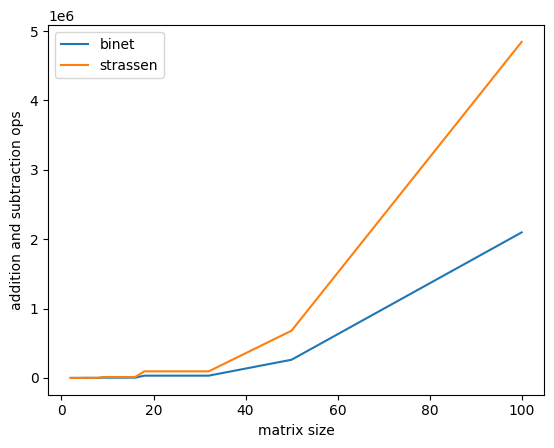

In [33]:
plt.plot(plot_sizes, binet_a_s_ops, label="binet")
plt.plot(plot_sizes, strassen_a_s_ops, label="strassen")
# plt.plot(plot_sizes, laderman_ops, label="laderman")
# if ai_ops is not None:
#     plt.plot([4], [ai_ops], "o", label="alphatensor")
plt.xlabel("matrix size")
plt.ylabel("addition and subtraction ops")
plt.legend()
plt.show()